# Heart Murmur Classification Using Deep Learning

### *Comparative Study of CNN and LSTM Models on the CirCor DigiScope Dataset*

**Machine Learning II · 2026/2027**  
**Work developed by** Afonso Santos e Rafael Santos

## 1. Introdução

Os sons cardíacos contêm informação relevante sobre o funcionamento do coração. Durante a auscultação, além dos sons associados ao ciclo cardíaco, podem ser identificadas alterações acústicas, como os **sopros cardíacos** (*heart murmurs*). A análise automática destas gravações constitui um problema de classificação de áudio em que é necessário distinguir padrões frequentemente subtis e sujeitos a variabilidade entre pacientes, locais de auscultação e condições de aquisição.

Neste projeto, desenvolvemos modelos de *deep learning* para classificar a presença de sopro cardíaco a partir de fonocardiogramas do **CirCor DigiScope**. A classificação corresponde a três categorias — **Present**, **Unknown** e **Absent** — e é realizada **ao nível do paciente**. Esta distinção é essencial: cada paciente pode ter várias gravações, obtidas em diferentes posições de auscultação, mas a decisão final deve ser única para esse indivíduo.

O conjunto público de trabalho inclui **942 pacientes e 3163 gravações**. Os principais desafios são o **desequilíbrio entre as classes**, a **duração variável dos áudios** e a existência de **múltiplas gravações por paciente**. Além disso, o rótulo do paciente não garante que o sopro esteja audível em todas as suas gravações, o que condiciona a forma como os exemplos são preparados e as previsões são combinadas.

Serão estudadas duas arquiteturas:
- Convolutional Neural Network (CNN): destinada a identificar padrões locais nas representações tempo-frequência.
- Recurrent Neural Network (RNN) baseada em LSTM: destinada a explorar a evolução temporal das características acústicas.   

O desenvolvimento segue uma sequência de análise exploratória, pré-processamento e extração de características, treino e seleção de modelos, agregação de previsões e avaliação final. O objetivo é comparar as duas abordagens de forma reprodutível, com separação rigorosa dos pacientes e uma métrica de avaliação adequada à tarefa.

## 2. Dados e exploração inicial

### Bibliotecas e configuração

Utilizamos `pandas` e `numpy` para manipulação de dados, `soundfile` e `librosa` para processamento de áudio, e `matplotlib` para visualização. Os modelos serão implementados com TensorFlow/Keras. As funções auxiliares de análise e visualização encontram-se em `utils.py`, enquanto as decisões metodológicas e os resultados permanecem no notebook.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Audio, display
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

from utils import *

SEED = 42

## 3. Análise exploratória dos dados

### Dataset CirCor DigiScope

O dataset contém 942 pacientes e 3163 gravações. O ficheiro `training_data.csv` reúne os metadados dos pacientes e a variável `Murmur`, utilizada como alvo da classificação. As gravações são disponibilizadas em formato WAV, identificadas pelo paciente e pela posição de auscultação.

Começamos por verificar a estrutura dos ficheiros e a correspondência entre os registos e os respetivos áudios.

In [2]:
DATA_DIR = Path("dataset")
AUDIO_DIR = DATA_DIR / "training_data"
CSV_PATH = DATA_DIR / "training_data.csv"

for path in (DATA_DIR, AUDIO_DIR, CSV_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Não encontrado: {path.resolve()}")

wav_files = sorted(AUDIO_DIR.glob("*.wav"))
print(f"Gravações WAV: {len(wav_files)}")

Gravações WAV: 3163


In [3]:
raw_metadata = pd.read_csv(CSV_PATH, dtype=str)
raw_metadata.columns = raw_metadata.columns.str.strip()
id_columns = [col for col in raw_metadata.columns
              if col.lower().replace('_', ' ').strip() == 'patient id']

if len(id_columns) != 1 or 'Murmur' not in raw_metadata.columns:
    raise ValueError('Não foi possível localizar Patient ID e Murmur no CSV.')

patients = raw_metadata[[id_columns[0], 'Murmur']].copy()
patients.columns = ['patient_id', 'murmur']
patients = patients.apply(lambda col: col.str.strip())
patients = patients.sort_values('patient_id').reset_index(drop=True)

assert patients['patient_id'].notna().all() and patients['patient_id'].is_unique
assert patients['murmur'].isin(CLASSES).all()
print('Pacientes:', len(patients))
display(patients.head(10))

Pacientes: 942


,patient_id,murmur
0,13918,Present
1,14241,Present
2,14998,Absent
3,23625,Absent
4,24160,Absent
5,2530,Absent
6,29045,Present
7,29378,Unknown
8,31737,Absent
9,33151,Present


### Associação entre pacientes e gravações

A partir dos nomes dos ficheiros construímos um índice que associa cada áudio ao paciente e à posição de auscultação. O diagnóstico é acrescentado para organizar os dados e permitir a avaliação, mas não será utilizado como característica de entrada dos modelos.

In [4]:
recordings = pd.DataFrame({
    'path': wav_files,
    'filename': [p.name for p in wav_files],
    'patient_id': [p.stem.split('_', 1)[0] for p in wav_files],
    'location': [p.stem.split('_', 1)[1] if '_' in p.stem else 'N/A'
                 for p in wav_files],
})

assert set(recordings['patient_id']) == set(patients['patient_id']), 'Pacientes inconsistentes.'
assert len(patients) == 942 and len(recordings) == 3163, 'Contagens diferentes das esperadas.'

recordings = recordings.merge(patients, on='patient_id', how='left', validate='many_to_one')
print('Pacientes com gravações:', recordings['patient_id'].nunique())
print('Gravações:', len(recordings))
display(recordings[['filename', 'patient_id', 'location', 'murmur']].head(10))

Pacientes com gravações: 942
Gravações: 3163


,filename,patient_id,location,murmur
0,13918_AV.wav,13918,AV,Present
1,13918_MV.wav,13918,MV,Present
2,13918_PV.wav,13918,PV,Present
3,13918_TV.wav,13918,TV,Present
4,14241_AV.wav,14241,AV,Present
5,14241_MV.wav,14241,MV,Present
6,14241_PV.wav,14241,PV,Present
7,14241_TV.wav,14241,TV,Present
8,14998_AV.wav,14998,AV,Absent
9,14998_MV.wav,14998,MV,Absent


### Divisão dos dados por paciente

Definimos três conjuntos independentes: **70% para treino, 15% para validação e 15% para teste**. A divisão é estratificada pelo diagnóstico e realizada antes de criar janelas de áudio ou ajustar transformações estatísticas.

Cada paciente pertence a uma única partição, incluindo todas as suas gravações. O conjunto de validação será utilizado na seleção dos modelos e dos parâmetros; o teste ficará reservado para a avaliação final.

Pacientes por partição e diagnóstico:


,Present,Unknown,Absent,Total
train,125,48,485,658
validation,27,10,105,142
test,27,10,105,142


Partição guardada em results/patient_split.csv


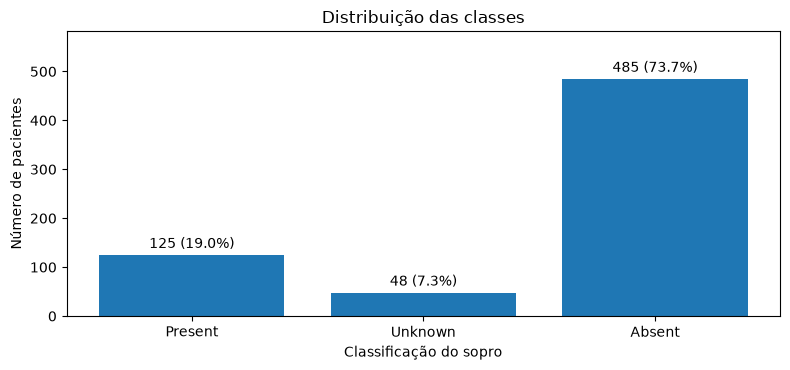

In [5]:
development_patients, test_patients = train_test_split(
    patients, test_size=0.15, random_state=SEED, stratify=patients['murmur'])
train_patients, val_patients = train_test_split(
    development_patients, test_size=0.15 / 0.85, random_state=SEED,
    stratify=development_patients['murmur'])

parts = {'train': train_patients, 'validation': val_patients, 'test': test_patients}
patient_ids = {name: set(data['patient_id']) for name, data in parts.items()}
assert all(patient_ids[a].isdisjoint(patient_ids[b]) for a, b in
           [('train', 'validation'), ('train', 'test'), ('validation', 'test')])

patient_split = pd.concat([data.assign(split=name) for name, data in parts.items()])
patient_split = patient_split.sort_values('patient_id').reset_index(drop=True)
recordings = recordings.merge(patient_split[['patient_id', 'split']],
                              on='patient_id', how='left', validate='many_to_one')
assert recordings['split'].notna().all()

RESULTS_DIR = Path('results')
RESULTS_DIR.mkdir(exist_ok=True)
patient_split[['patient_id', 'split']].to_csv(RESULTS_DIR / 'patient_split.csv', index=False)

counts = pd.crosstab(patient_split['split'], patient_split['murmur']).reindex(
    index=['train', 'validation', 'test'], columns=CLASSES, fill_value=0)
counts['Total'] = counts.sum(axis=1)
counts.index.name = None
counts.columns.name = None
print('Pacientes por partição e diagnóstico:')
display(counts)
print('Partição guardada em results/patient_split.csv')
plot_class_distribution(train_patients)

> A divisão resultou em 658 pacientes para treino, 142 para validação e 142 para teste, preservando aproximadamente as proporções originais das três classes. A separação por paciente garante que gravações pertencentes ao mesmo indivíduo não sejam distribuídas por diferentes conjuntos, evitando uma avaliação artificialmente otimista. 

### Avaliação e referência inicial

A métrica principal será a **weighted accuracy por paciente**, com pesos de 5 para `Present`, 3 para `Unknown` e 1 para `Absent`. Após o treino, as previsões das gravações de um mesmo paciente serão agregadas numa única classificação, sobre a qual a métrica será calculada.

Como referência inicial, comparamos classificadores constantes que atribuem sempre a mesma classe aos pacientes de **treino**. Esta comparação evidencia a diferença entre accuracy convencional e weighted accuracy num conjunto desequilibrado, sem recorrer à validação ou ao teste.

In [6]:
assert np.isclose(weighted_accuracy(['Present', 'Unknown', 'Absent'],
                                     ['Absent', 'Unknown', 'Absent']), 4 / 9)
assert np.isclose(weighted_accuracy(CLASSES, CLASSES), 1.0)

train_labels = train_patients['murmur'].to_numpy()
baselines = []
for label in CLASSES:
    predictions = np.repeat(label, len(train_labels))
    baselines.append({
        'Previsão constante': label,
        'Accuracy': accuracy_score(train_labels, predictions),
        'Weighted accuracy': weighted_accuracy(train_labels, predictions),
    })
display(pd.DataFrame(baselines).round(3))

,Previsão constante,Accuracy,Weighted accuracy
0,Present,0.190,0.498
1,Unknown,0.073,0.115
2,Absent,0.737,0.387


> 	Os resultados das referências iniciais mostram que a accuracy convencional pode ser pouco representativa do desempenho neste problema. A previsão sistemática da classe *Absent* permite obter uma accuracy de aproximadamente 73,7%, mas uma weighted accuracy de apenas 38,7%.

> Por outro lado, a previsão constante de *Present* atinge uma weighted accuracy de aproximadamente 49,8%, apesar de apresentar uma accuracy convencional bastante inferior. Esta diferença reflete a maior importância atribuída à classificação correta dos pacientes *Present* e *Unknown*.

> Estes resultados constituem uma referência inicial para a avaliação dos modelos, destacando a necessidade de analisar o desempenho nas diferentes classes e não apenas a proporção global de previsões corretas.

### Caracterização das gravações

A frequência de amostragem, o número de canais e a duração dos sinais condicionam a preparação das entradas das redes neuronais. A leitura dos cabeçalhos dos WAV permite obter estas informações sem carregar os áudios completos em memória. Analisamos também quantas gravações estão disponíveis por paciente e como se distribuem pelas posições de auscultação.

Gravações de treino: 2225
Frequência de amostragem (Hz): [np.int64(4000)]
Número de canais: [np.int64(1)]
Duração (s) — mínimo, mediana, máximo: 5.15 21.49 64.51


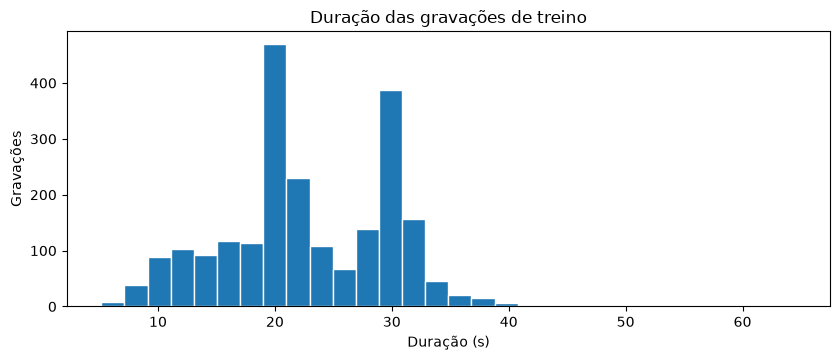

In [7]:
train_recordings = recordings.loc[recordings["split"] == "train"].copy().reset_index(drop=True)
train_audio_stats = train_recordings.merge(
    audio_headers(train_recordings["path"]), on="filename", validate="one_to_one"
)

print(f"Gravações de treino: {len(train_audio_stats)}")
print("Frequência de amostragem (Hz):", sorted(train_audio_stats["sample_rate"].unique()))
print("Número de canais:", sorted(train_audio_stats["channels"].unique()))
print("Duração (s) — mínimo, mediana, máximo:",
      *(round(x, 2) for x in (
          train_audio_stats["duration_s"].min(),
          train_audio_stats["duration_s"].median(),
          train_audio_stats["duration_s"].max(),
      )))
plot_duration_distribution(train_audio_stats)

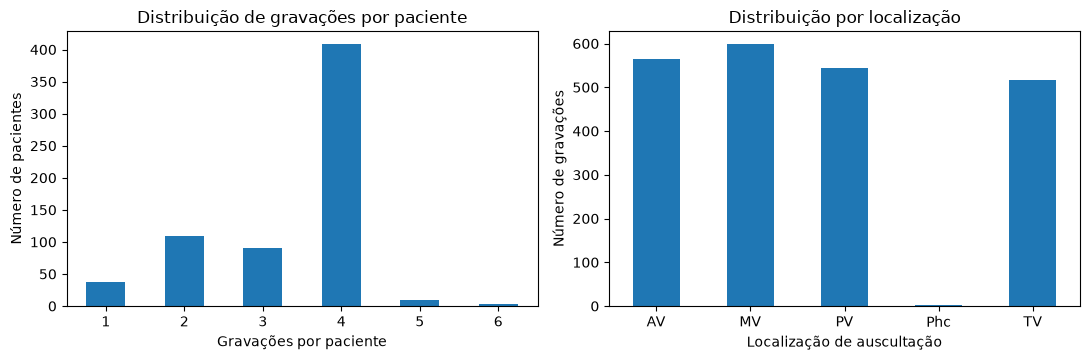

In [8]:
plot_recording_coverage(train_recordings)

> As gravações de treino analisadas apresentam **4000 Hz e um único canal**, pelo que não é necessário alterar estas propriedades para uniformizar o sinal. Já as durações diferem consideravelmente entre gravações, com uma mediana próxima dos **21,5 segundos**. O número de registos por paciente também varia, embora quatro gravações sejam frequentes.

> Estas observações motivam duas decisões: utilizar **janelas temporais de dimensão fixa**, sem eliminar sistematicamente o final das gravações, e preservar o identificador do paciente para obter uma **previsão conjunta** a partir dos seus vários registos.

### Visualização dos sinais cardíacos e representação tempo-frequência

A forma de onda mostra a variação da amplitude ao longo do tempo; o mel-espectrograma representa a energia distribuída pelas bandas de frequência. A escala logarítmica facilita a visualização de diferenças de intensidade.

Para ilustrar as duas representações, selecionamos **uma gravação por classe, de pacientes distintos**, exclusivamente do treino. Os excertos de oito segundos e os parâmetros de extração utilizados nesta visualização são exploratórios: ainda não correspondem à configuração final dos modelos. Um exemplo isolado não é representativo de todos os pacientes da mesma classe.

,filename,patient_id,location,murmur
0,49691_TV.wav,49691,TV,Present
1,84919_PV.wav,84919,PV,Unknown
2,59536_MV.wav,59536,MV,Absent


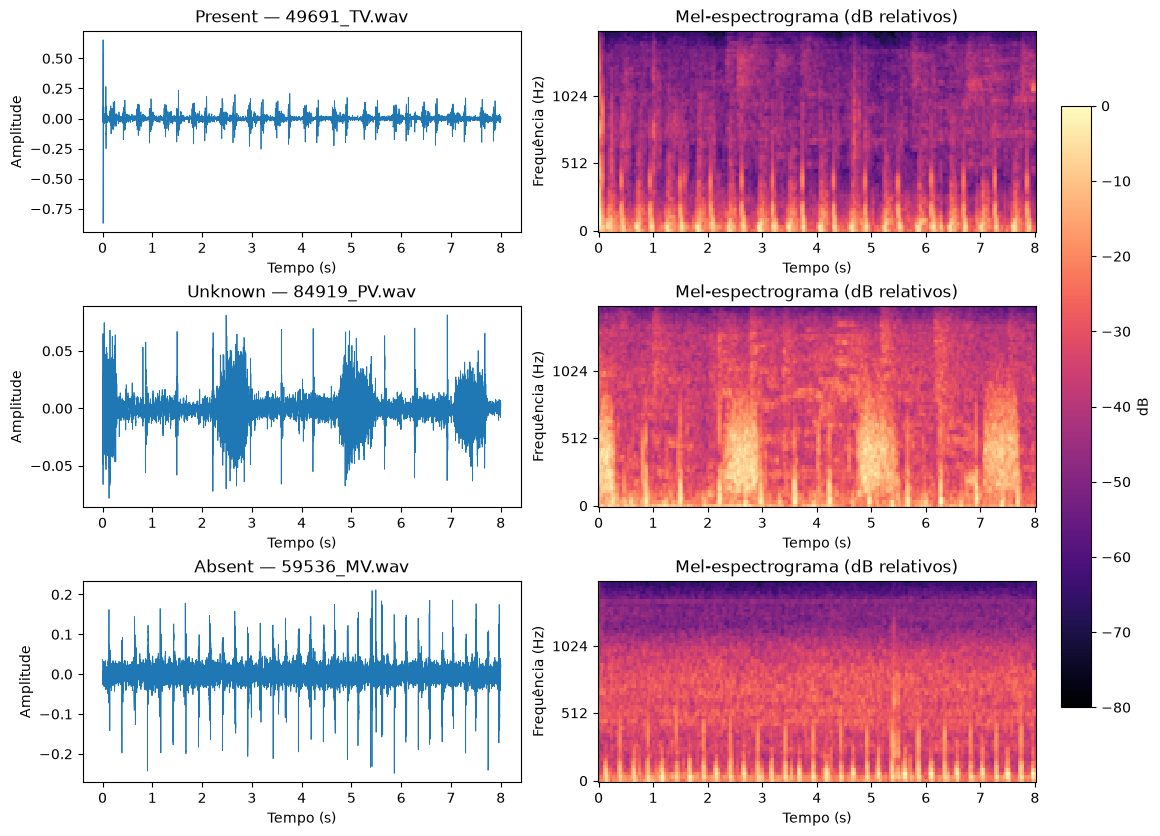

In [9]:
N_FFT, HOP_LENGTH, N_MELS = 512, 128, 64
examples = choose_examples(train_recordings, n_per_class=1, seed=SEED)
display(examples[['filename', 'patient_id', 'location', 'murmur']])
plot_signal_and_mel(examples, seconds=8, n_fft=N_FFT,
                    hop_length=HOP_LENGTH, n_mels=N_MELS)

> Nos exemplos observam-se padrões temporais repetitivos e diferentes distribuições de energia espectral. Contudo, a comparação de apenas três gravações **não permite inferir uma separação fiável das classes**: o diagnóstico é atribuído ao paciente e um sopro pode não ser audível num excerto específico. A utilidade discriminativa das características acústicas terá de ser demonstrada através dos modelos e da avaliação em pacientes independentes.



### Audição de um excerto

A reprodução de um excerto complementa a observação visual, permitindo relacionar os padrões da forma de onda e do espectrograma com o som original. Não constitui uma avaliação clínica.

In [10]:
example_row = examples.iloc[0]
signal, sr = read_audio_excerpt(example_row['path'], seconds=8)
print(example_row['filename'], '| Diagnóstico do paciente:', example_row['murmur'])
display(Audio(signal, rate=sr))

49691_TV.wav | Diagnóstico do paciente: Present


## 4. Pré-processamento dos sinais cardíacos

A exploração revelou sinais com taxa de amostragem uniforme, mas **duração variável**. Para obter entradas de dimensão fixa, começamos por segmentar cada gravação em **janelas de 4 segundos**, com um **avanço de 2 segundos**. A última janela é alinhada com o final do áudio, evitando descartar sistematicamente os últimos instantes; gravações inferiores à duração da janela são preenchidas com zeros.

Estes parâmetros constituem uma **configuração inicial para comparação**, não uma escolha otimizada. A sua adequação deverá ser examinada com os dados de validação, preservando o conjunto de teste.

### Segmentação temporal

A segmentação é indexada sem carregar todas as gravações para memória. O índice conserva o identificador do paciente, o ficheiro e a localização de origem, necessários para combinar as previsões das janelas e dos diferentes pontos de auscultação.

In [11]:
WINDOW_SECONDS = 4.0
STRIDE_SECONDS = 2.0
SAMPLE_RATE = 4000

train_windows = build_window_manifest(
    train_recordings, window_seconds=WINDOW_SECONDS,
    stride_seconds=STRIDE_SECONDS, sample_rate=SAMPLE_RATE,
)

assert set(train_windows['patient_id']) == set(train_patients['patient_id'])
assert (train_windows.groupby('filename')['stop_sample'].max()
        == train_windows.groupby('filename')['total_samples'].first()).all()

print('Gravações de treino:', len(train_recordings))
print('Janelas de treino:', len(train_windows))
print('Pacientes representados:', train_windows['patient_id'].nunique())

Gravações de treino: 2225
Janelas de treino: 24281
Pacientes representados: 658


### Extração de características: log-mel-espectrogramas

Cada janela é transformada num **log-mel-espectrograma**, que descreve a energia espectral em bandas de frequência e instantes sucessivos. Como configuração inicial, utilizamos **64 bandas mel**, `n_fft=512`, `hop_length=128` e o intervalo de **20–1500 Hz**. Estas escolhas permitem representar informação temporal e frequencial a um custo computacional controlado; continuarão sujeitas a validação experimental.

Para a comparação inicial, utilizaremos **a mesma informação acústica** nas duas arquiteturas: a CNN recebe uma matriz de frequência × tempo × canal, enquanto a LSTM recebe uma sequência de vetores temporais. A transformação usa uma referência fixa de energia em dB, antes da normalização estatística.

| Parâmetro | Valor inicial | Finalidade |
|---|---:|---|
| Frequência de amostragem | 4000 Hz | Conservar a frequência original observada no treino |
| Duração das janelas | 4 s | Uniformizar a duração das entradas |
| Avanço entre janelas | 2 s | Permitir sobreposição e cobertura do sinal |
| Número de bandas mel | 64 | Representar a distribuição espectral |
| `n_fft` | 512 | Definir a resolução da análise frequencial |
| `hop_length` | 128 | Definir o intervalo temporal entre colunas do espectrograma |
| Intervalo de frequências | 20–1500 Hz | Concentrar a representação na região de interesse |

Os valores são **hiperparâmetros iniciais**, a confirmar com o conjunto de validação.

Log-mel: (64, 122)
Entrada CNN: (64, 122, 1)
Entrada LSTM: (122, 64)


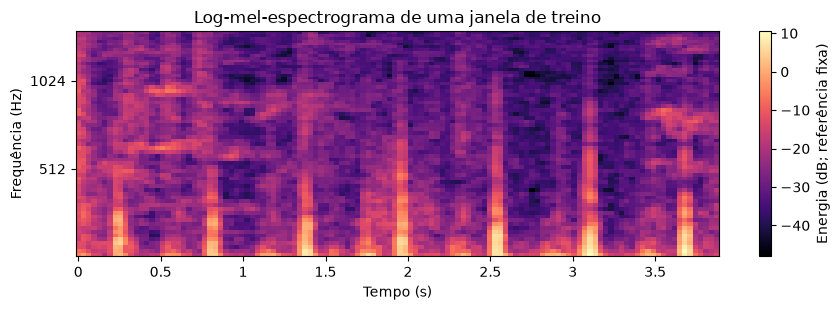

In [12]:
N_MELS = 64
N_FFT = 512
HOP_LENGTH = 128
FMIN, FMAX = 20, 1500

# Exemplo de uma janela do conjunto de treino; não processamos o dataset inteiro aqui.
example_window = train_windows.iloc[0]
feature_options = dict(
    window_seconds=WINDOW_SECONDS, sample_rate=SAMPLE_RATE,
    n_mels=N_MELS, n_fft=N_FFT, hop_length=HOP_LENGTH,
    fmin=FMIN, fmax=FMAX,
)
logmel = extract_logmel_window(example_window, **feature_options)
cnn_input, lstm_input = format_model_inputs(logmel)

assert np.isfinite(logmel).all()
assert cnn_input.shape[:2] == logmel.shape
assert lstm_input.shape == logmel.T.shape
print('Log-mel:', logmel.shape)
print('Entrada CNN:', cnn_input.shape)
print('Entrada LSTM:', lstm_input.shape)

plot_logmel_window(logmel, sample_rate=SAMPLE_RATE,
                   hop_length=HOP_LENGTH, fmin=FMIN, fmax=FMAX)

### Preparação dos conjuntos de validação e teste

Aplicamos **a mesma segmentação temporal** às gravações de validação e teste, sem alterar os parâmetros em função desses conjuntos. Conservamos, em todas as janelas, o identificador do paciente, a gravação de origem e o diagnóstico de referência.

A separação por paciente foi efetuada **antes da segmentação**. Deste modo, nenhuma janela de um paciente de treino pode surgir nos conjuntos de validação ou de teste. A criação dos índices não implica carregar todos os sinais para memória.

In [13]:
val_recordings = recordings.loc[recordings['split'] == 'validation'].copy().reset_index(drop=True)
test_recordings = recordings.loc[recordings['split'] == 'test'].copy().reset_index(drop=True)

window_options = dict(
    window_seconds=WINDOW_SECONDS,
    stride_seconds=STRIDE_SECONDS,
    sample_rate=SAMPLE_RATE,
)
val_windows = build_window_manifest(val_recordings, **window_options)
test_windows = build_window_manifest(test_recordings, **window_options)

for window_data, patient_data in (
    (train_windows, train_patients),
    (val_windows, val_patients),
    (test_windows, test_patients),
):
    assert set(window_data['patient_id']) == set(patient_data['patient_id'])
    assert window_data.groupby('filename')['stop_sample'].max().eq(
        window_data.groupby('filename')['total_samples'].first()
    ).all()

assert set(train_windows['patient_id']).isdisjoint(val_windows['patient_id'])
assert set(train_windows['patient_id']).isdisjoint(test_windows['patient_id'])
assert set(val_windows['patient_id']).isdisjoint(test_windows['patient_id'])

window_summary = pd.DataFrame([
    {'Conjunto': name, 'Pacientes': data['patient_id'].nunique(),
     'Gravações': data['filename'].nunique(), 'Janelas': len(data)}
    for name, data in (
        ('Treino', train_windows),
        ('Validação', val_windows),
        ('Teste', test_windows),
    )
])
display(window_summary)

,Conjunto,Pacientes,Gravações,Janelas
0,Treino,658,2225,24281
1,Validação,142,468,5157
2,Teste,142,470,5085


### Normalização das características

Para evitar que diferenças de escala prejudiquem o treino, aplicamos uma **normalização por banda mel**, subtraindo a média e dividindo pelo desvio-padrão. Estas estatísticas são calculadas **exclusivamente a partir das janelas de treino**; na validação e no teste, utilizaremos exatamente os mesmos valores.

A normalização é feita depois de calcular os log-mel-espectrogramas. As somas necessárias ao cálculo das médias e dos desvios-padrão são acumuladas progressivamente, sem guardar todos os espectrogramas em memória. Este passo percorre todas as janelas de treino e pode ser computacionalmente exigente. Os parâmetros resultantes são guardados para permitir a reprodução das experiências.

In [14]:
# Ajuste da normalização apenas com as janelas de treino.
mel_mean, mel_std = fit_logmel_normalizer(
    train_windows, feature_kwargs=feature_options, progress_every=4000
)

assert mel_mean.shape == (N_MELS,) and mel_std.shape == (N_MELS,)
assert np.isfinite(mel_mean).all() and np.isfinite(mel_std).all()
assert (mel_std > 0).all()

NORMALIZER_PATH = RESULTS_DIR / 'logmel_normalizer.npz'
np.savez(
    NORMALIZER_PATH, mean=mel_mean, std=mel_std,
    sample_rate=SAMPLE_RATE, window_seconds=WINDOW_SECONDS,
    stride_seconds=STRIDE_SECONDS, n_mels=N_MELS,
    n_fft=N_FFT, hop_length=HOP_LENGTH,
    fmin=FMIN, fmax=FMAX,
)

print('Estatísticas da normalização:')
print('Bandas mel:', len(mel_mean))
print('Intervalo das médias (dB):', round(float(mel_mean.min()), 2),
      'a', round(float(mel_mean.max()), 2))
print('Normalização guardada em:', NORMALIZER_PATH)

Normalização: 4000/24281 janelas analisadas
Normalização: 8000/24281 janelas analisadas
Normalização: 12000/24281 janelas analisadas
Normalização: 16000/24281 janelas analisadas
Normalização: 20000/24281 janelas analisadas
Normalização: 24000/24281 janelas analisadas
Estatísticas da normalização:
Bandas mel: 64
Intervalo das médias (dB): -39.88 a -13.89
Normalização guardada em: results\logmel_normalizer.npz


### Formatação das entradas para CNN e LSTM

As duas arquiteturas recebem a **mesma representação acústica normalizada**, organizada de formas distintas:

- **CNN 2D:** matriz com dimensões `(bandas mel, instantes, canais)`;
- **LSTM:** sequência com dimensões `(instantes, bandas mel)`.

As janelas são transformadas **quando necessárias**, em vez de armazenarmos antecipadamente todas as entradas dos modelos em memória. Os rótulos associados às janelas são convertidos em índices inteiros para o treino; contudo, como o diagnóstico pertence ao paciente, uma janela individual pode não conter um sopro audível. A avaliação final terá de reunir as probabilidades das janelas e das gravações numa única previsão por paciente.

In [16]:
# Codificação dos diagnósticos para treino com classificação multiclasse.
CLASS_TO_INDEX = {label: index for index, label in enumerate(CLASSES)}
for window_data in (train_windows, val_windows, test_windows):
    window_data['class_index'] = window_data['murmur'].map(CLASS_TO_INDEX)
    assert window_data['class_index'].notna().all()
    window_data['class_index'] = window_data['class_index'].astype('int64')

# Verificação da preparação de uma janela, sem carregar o conjunto inteiro.
normalized_logmel = normalize_logmel(logmel, mel_mean, mel_std)
cnn_ready, lstm_ready = prepare_window_inputs(
    example_window, mel_mean, mel_std, feature_kwargs=feature_options
)

assert np.isfinite(normalized_logmel).all()
assert np.allclose(cnn_ready[..., 0], normalized_logmel, atol=1e-5)
assert cnn_ready.shape == (N_MELS, logmel.shape[1], 1)
assert lstm_ready.shape == (logmel.shape[1], N_MELS)

print('Log-mel normalizado:', normalized_logmel.shape)
print('Entrada da CNN:', cnn_ready.shape)
print('Entrada da LSTM:', lstm_ready.shape)
print('Número de classes:', len(CLASSES))
print('Ordem das classes:', ', '.join(CLASSES))

Log-mel normalizado: (64, 122)
Entrada da CNN: (64, 122, 1)
Entrada da LSTM: (122, 64)
Número de classes: 3
Ordem das classes: Present, Unknown, Absent
